# TP 1 — Découverte expérimentale de la complexité algorithmique
### Algorithmique avancée et complexité — Master IA et Master RSD

| | |
|---|---|
| **Cours & TD** | Dr. Benyamina Ahmed |
| **TP** | Mahkouka Mohamed Fouad |
| **Durée** | 1 séance |

---

**Objectif :** observer comment le **nombre d'opérations** et le **temps d'exécution** évoluent lorsque la **taille de l'entrée** augmente.

> ℹ️ Vous disposez de **cinq programmes Python**. Pour chacun : exécutez-le pour plusieurs valeurs de $n$, **comptez le nombre d'opérations** de l'opération élémentaire indiquée, **mesurez le temps d'exécution**, **complétez le tableau** et **tracez le graphique** demandé.

## Votre travail (pour chaque programme)

1. Exécuter le programme pour plusieurs valeurs de $n$.
2. Compter le nombre d'exécutions de l'opération élémentaire indiquée dans le code.
3. Mesurer le temps d'exécution (en secondes) sur la machine du TP.
4. Remplir le tableau de résultats.
5. Tracer le(s) graphique(s) demandé(s).
6. Décrire ce que vous observez quand $n$ augmente.
7. Conclure sur le comportement de l'algorithme (**sans utiliser la notation $O(\cdot)$**).

## Tableau de résultats (à remplir pour chaque programme)

| $n$ (taille de l'entrée) | Nombre d'opérations (compté) | Temps d'exécution (secondes) |
|---|---|---|
| 10 | | |
| 100 | | |
| 1 000 | | |
| … | | |

## Graphiques à tracer

- **Graphique 1** : nombre d'opérations (ordonnée) en fonction de $n$ (abscisse).
- **Graphique 2** : temps d'exécution (secondes, ordonnée) en fonction de $n$ (abscisse).
- **Échelle logarithmique en base 10** pour les deux axes.

## 💡 Consignes importantes

- Répéter chaque mesure **au moins 3 fois** et prendre la **moyenne** pour le temps.
- Indiquer sur vos graphiques **le nom du programme testé**.
- Ne pas chercher à identifier une formule mathématique. **Décrire simplement la forme de la courbe** et ce que vous observez.

---
# Outils de mesure

**Exécutez cette cellule en premier** (vous n'avez rien à y modifier). Ce sont les outils vus au **TP 0, Partie 5**.

| Fonction | Rôle |
|---|---|
| `chrono(f, *args)` | temps **moyen** de `f(*args)` sur **3 mesures** |
| `afficher(tailles, operations, temps)` | affiche le **tableau de résultats** |
| `tracer(nom_programme, tailles, operations, temps)` | trace les **graphiques 1 et 2** en échelle log base 10, avec le nom du programme |

In [48]:
import time
import matplotlib.pyplot as plt


def chrono(f, *args, repetitions=3):
    # Temps moyen (en secondes) de f(*args) sur 3 mesures.
    total = 0.0
    for _ in range(repetitions):
        debut = time.perf_counter()
        f(*args)
        total += time.perf_counter() - debut
    return total / repetitions



def afficher(tailles, operations, temps):
    # Affiche le tableau de résultats.
    print(f"{'n':>10} | {'opérations (compté)':>20} | {'temps (s)':>10}")
    print("-" * 47)
    for n, o, t in zip(tailles, operations, temps):
        print(f"{n:>10,} | {o:>20,} | {t:>10.6f}")


def tracer(nom_programme, tailles, operations, temps):
    # Graphique 1 : opérations en fonction de n. Graphique 2 : temps en fonction de n.
    # Échelle logarithmique en base 10 sur les deux axes.
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.loglog(tailles, operations, "o-")
    ax1.set(title="Graphique 1 : nombre d'opérations", xlabel="n (taille de l'entrée)", ylabel="nombre d'opérations")
    ax2.loglog(tailles, temps, "o-", color="tab:red")
    ax2.set(title="Graphique 2 : temps d'exécution", xlabel="n (taille de l'entrée)", ylabel="temps (s)")
    for ax in (ax1, ax2):
        ax.grid(True, which="both", alpha=0.3)
    fig.suptitle(nom_programme)
    plt.tight_layout()
    plt.show()


print("Outils prêts ✅")

Outils prêts ✅


---
# Programme 1 — Parcours simple

```python
def parcours(n):
    compteur = 0
    for i in range(n):
        compteur += 1   # opération élémentaire
    return compteur
```

**Que fait ce programme ?** Il parcourt $n$ éléments un par un et effectue la même opération à chaque itération.

**Opération élémentaire à compter :** l'incrément `compteur += 1`.

> 📌 Ce premier programme est **entièrement fait** : il vous sert de **modèle** pour les quatre suivants.

In [49]:
def parcours(n):
    compteur = 0
    for i in range(n):
        compteur += 1   # opération élémentaire
    return compteur

         n |  opérations (compté) |  temps (s)
-----------------------------------------------
        10 |                   10 |   0.000001
       100 |                  100 |   0.000001
     1,000 |                1,000 |   0.000030
    10,000 |               10,000 |   0.000349
   100,000 |              100,000 |   0.003620
 1,000,000 |            1,000,000 |   0.034787


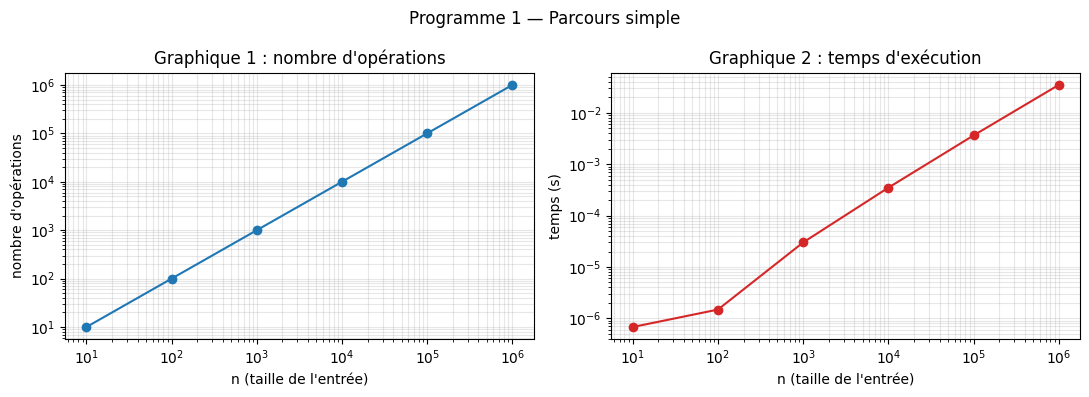

In [50]:
tailles = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
operations, temps = [], []

for n in tailles:
    operations.append(parcours(n))       # 2. compter
    temps.append(chrono(parcours, n))    # 3. mesurer (moyenne de 3)

afficher(tailles, operations, temps)                               # 4. tableau
tracer("Programme 1 — Parcours simple", tailles, operations, temps)  # 5. graphiques

> ✍️ **Ce que j'observe quand n augmente :** quand $n$ est multiplié par 10, le nombre d'opérations est multiplié par 10 et le temps aussi (environ). Les deux courbes sont des droites.
>
> ✍️ **Conclusion sur le comportement de l'algorithme :** le travail augmente au même rythme que $n$ : deux fois plus de données, deux fois plus de travail.

*(exemple de réponse : faites de même pour les programmes suivants)*

---
# Programme 2 — Recherche séquentielle

```python
def recherche_seq(T, x):
    compteur = 0
    for e in T:
        compteur += 1   # comparaison
        if e == x:
            return compteur
    return compteur
```

**Que fait ce programme ?** Il recherche la valeur `x` dans le tableau `T` en parcourant les éléments de gauche à droite.

**Opération élémentaire à compter :** `compteur += 1` (la comparaison).

Ici le résultat dépend de **l'endroit où se trouve `x`**. On utilise `T = [1, 2, 3, …, n]` et on teste **4 situations** :

| Situation | Valeur cherchée |
|---|---|
| Début (position 1) | `x = T[0]` |
| Milieu (≈ n/2) | `x = T[n // 2]` |
| Fin (position n) | `x = T[n - 1]` |
| Absent | `x = 0` (n'est pas dans `T`) |

In [51]:
def recherche_seq(T, x):
    compteur = 0
    for e in T:
        compteur += 1   # comparaison
        if e == x:
            return compteur
    return compteur

### ✍️ À programmer
Pour chaque situation, une liste d'opérations et une liste de temps sont prêtes. Complétez la boucle, puis tracez les graphiques des 4 situations.

In [52]:
tailles = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
ops_debut, ops_milieu, ops_fin, ops_absent = [], [], [], []
t_debut, t_milieu, t_fin, t_absent = [], [], [], []

for n in tailles:
    T = list(range(1, n + 1))       # T = [1, 2, ..., n]
    # Début : x = T[0]
    ops_debut.append(recherche_seq(T, T[0]))
    t_debut.append(chrono(recherche_seq, T, T[0]))
    # Milieu : x = T[n // 2]
    # À COMPLÉTER

    # Fin : x = T[n - 1]
    # À COMPLÉTER

    # Absent : x = 0
    # À COMPLÉTER


print("Début"); afficher(tailles, ops_debut, t_debut)
# À COMPLÉTER : afficher les tableaux des 3 autres situations

Début
         n |  opérations (compté) |  temps (s)
-----------------------------------------------
        10 |                    1 |   0.000001
       100 |                    1 |   0.000000
     1,000 |                    1 |   0.000000
    10,000 |                    1 |   0.000000
   100,000 |                    1 |   0.000000
 1,000,000 |                    1 |   0.000000


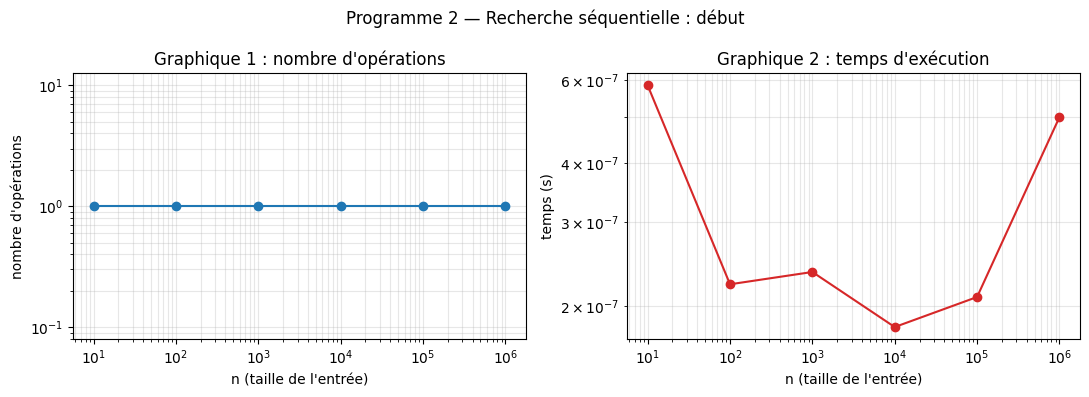

In [53]:
tracer("Programme 2 — Recherche séquentielle : début", tailles, ops_debut, t_debut)
# À COMPLÉTER : tracer les graphiques des situations milieu, fin et absent

> ✍️ **Ce que j'observe quand n augmente :** …
>
> ✍️ **Conclusion sur le comportement de l'algorithme :** …

---
# Programme 3 — Deux boucles imbriquées

```python
def deux_boucles(n):
    compteur = 0
    for i in range(n):
        for j in range(n):
            compteur += 1   # opération élémentaire
    return compteur
```

**Que fait ce programme ?** Il exécute une opération pour chaque paire $(i, j)$. Il y a deux niveaux de répétition.

**Opération élémentaire à compter :** `compteur += 1`.

> ⏱️ Ce programme devient vite lent : on **double** $n$ à chaque mesure au lieu de le multiplier par 10.

In [54]:
def deux_boucles(n):
    compteur = 0
    for i in range(n):
        for j in range(n):
            compteur += 1   # opération élémentaire
    return compteur

### ✍️ À programmer
Sur le modèle du programme 1 : boucle de mesure, tableau, graphiques.

In [55]:
tailles = [10, 20, 40, 80, 160, 320, 640, 1_280]
operations, temps = [], []

# À COMPLÉTER

> ✍️ **Ce que j'observe quand n augmente :** …
>
> ✍️ **Conclusion sur le comportement de l'algorithme :** …

---
# Programme 4 — Division répétée par 2

```python
def divisions_par_2(n):
    compteur = 0
    while n > 1:
        n = n // 2
        compteur += 1   # opération élémentaire
    return compteur
```

**Que fait ce programme ?** Il divise $n$ par 2 à chaque étape tant que $n$ est supérieur à 1. Le nombre d'étapes dépend de $n$.

**Opération élémentaire à compter :** `compteur += 1`.

In [56]:
def divisions_par_2(n):
    compteur = 0
    while n > 1:
        n = n // 2
        compteur += 1   # opération élémentaire
    return compteur

### ✍️ À programmer

In [57]:
tailles = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
operations, temps = [], []

# À COMPLÉTER

> ✍️ **Ce que j'observe quand n augmente :** …
>
> ✍️ **Conclusion sur le comportement de l'algorithme :** …

---
# Programme 5 — Fibonacci récursif naïf

```python
def fibonacci(n):
    if n <= 1:
        return n
    return fibonacci(n - 1) + fibonacci(n - 2)
```

**Que fait ce programme ?** Il calcule le $n$-ième nombre de Fibonacci avec une récursion naïve. Le nombre d'appels augmente très rapidement quand $n$ augmente.

**Opération élémentaire à compter :** chaque appel récursif effectué (incrémenter un compteur au **début** de la fonction).

> ⚠️ **Attention :** tester uniquement pour de petites valeurs de $n$ (ex. $n \le 35$).

### ✍️ À programmer
Le programme ne contient pas encore de compteur. Écrivez `fib_naif(n, compteur)` : c'est le même programme, avec un **compteur** passé en paramètre.

`compteur` est une liste `[0]` (une liste peut être modifiée à l'intérieur de la fonction) : ajoutez `compteur[0] += 1` **au début** de la fonction, et passez `compteur` aux deux appels récursifs.

In [58]:
def fib_naif(n, compteur):
    # À COMPLÉTER
    pass

compteur = [0]
valeur = fib_naif(10, compteur)
print("F(10) =", valeur, "| appels :", compteur[0])     # attendu : F(10) = 55 | appels : 177

F(10) = None | appels : 0


Puis la boucle de mesure. Pour chaque $n$, créez un **nouveau** compteur `[0]`. (Vous pouvez ajouter 32, 34, 35 à la fin si vous avez le temps : $n = 35$ prend plusieurs secondes.)

In [59]:
tailles = [5, 10, 15, 20, 25, 30]
operations, temps = [], []

# À COMPLÉTER

> ✍️ **Ce que j'observe quand n augmente :** …
>
> ✍️ **Conclusion sur le comportement de l'algorithme :** …

---
# Comparaison qualitative

Complétez avec vos mots : *augmente très lentement*, *augmente modérément*, *augmente très vite*, *augmente extrêmement vite*…

| Programme | Croissance observée (qualitative) |
|---|---|
| Parcours simple | |
| Recherche séquentielle | |
| Deux boucles imbriquées | |
| Division par 2 répétée | |
| Fibonacci récursif naïf | |

---
# 📤 Travail à rendre

1. Placez ce notebook dans `aac-tp/tp1_complexite/`.
2. Complétez toutes les cellules « À COMPLÉTER » et toutes les lignes ✍️.
3. Vérifiez que **chaque graphique porte le nom du programme**.
4. **Restart & Run All** : aucune erreur.
5. Envoyez sur GitHub :

```bash
git add tp1_complexite/
git commit -m "TP1 : découverte expérimentale de la complexité"
git push
```

### ➡️ Prochaine séance : **TP 2 — Analyse de la complexité temporelle** (notation Grand O)